In [4]:
import pandas as pd

# Load the dataset
df = pd.read_excel("US-Superstore-data.xls")

# Display the first few rows
print(df.head())

# Display dataset information
print(df.info())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Convert date columns to datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Verify data types after conversion
print("\nUpdated Data Types:")
print(df.dtypes)

# Display basic statistics for numerical columns
print("\nSummary Statistics:")
print(df.describe())

# Confirm dataset shape after preprocessing
print("\nDataset Shape:", df.shape)

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12 2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   South  FUR-BO-10

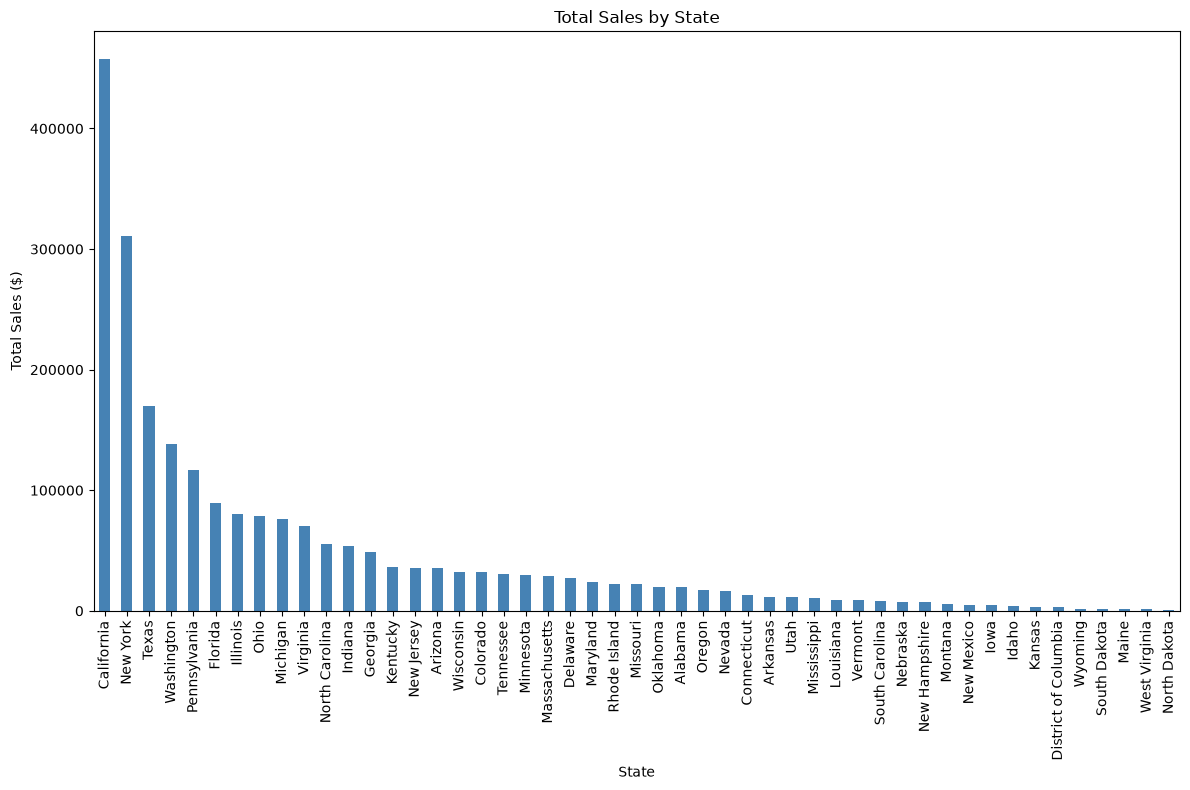

In [5]:
#Visualise sales by state

import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_excel("US-Superstore-data.xls")  # adjust filename if needed

# Calculate total sales by state
sales_by_state = (
    df.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(12, 8))
sales_by_state.plot(
    kind="bar",
    color="steelblue"
)

# Add title and labels
plt.title("Total Sales by State")
plt.xlabel("State")
plt.ylabel("Total Sales ($)")

# Rotate state names for readability
plt.xticks(rotation=90)

# Adjust layout
plt.tight_layout()

# Display the chart
plt.show()

California has the most sales by state.

                  Sales      Profit
State                              
California  457687.6315  76381.3871
New York    310876.2710  74038.5486
Sales Difference: $146,811.36
Profit Difference: $2,342.84
Sales Difference: $146,811.36
Profit Difference: $2,342.84


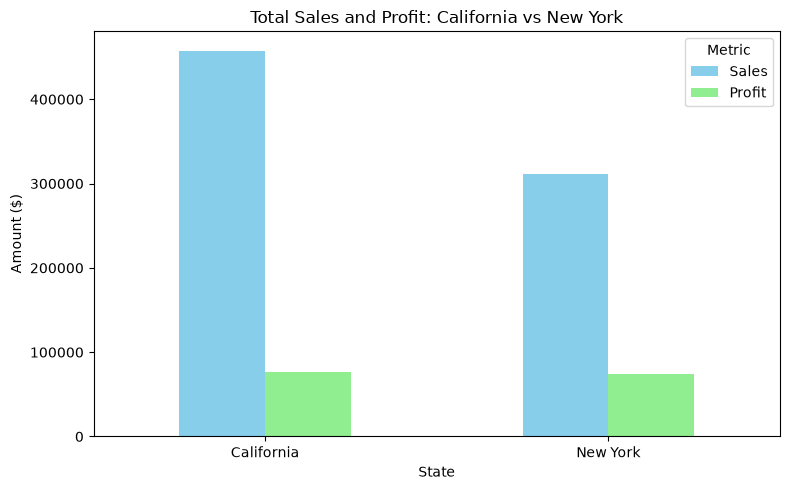

In [6]:
# Select only New York and California
state_comparison = (
    df[df["State"].isin(["New York", "California"])]
    .groupby("State")[["Sales", "Profit"]]
    .sum()
)

print(state_comparison)

california = state_comparison.loc["California"]
new_york = state_comparison.loc["New York"]

sales_difference = california["Sales"] - new_york["Sales"]
profit_difference = california["Profit"] - new_york["Profit"]

print(f"Sales Difference: ${sales_difference:,.2f}")
print(f"Profit Difference: ${profit_difference:,.2f}")

california = state_comparison.loc["California"]
new_york = state_comparison.loc["New York"]

sales_difference = california["Sales"] - new_york["Sales"]
profit_difference = california["Profit"] - new_york["Profit"]

print(f"Sales Difference: ${sales_difference:,.2f}")
print(f"Profit Difference: ${profit_difference:,.2f}")

import matplotlib.pyplot as plt

state_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    color=["skyblue", "lightgreen"]
)

plt.title("Total Sales and Profit: California vs New York")
plt.xlabel("State")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.tight_layout()
plt.show()

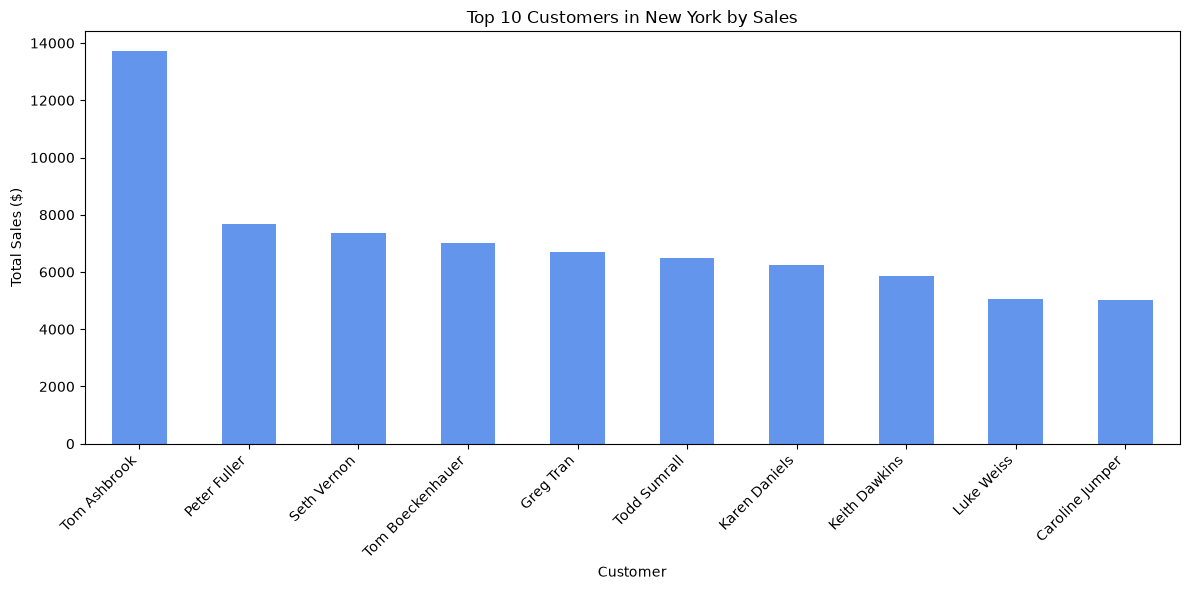

Tom Ashbrook is an outstanding customer in New York, ordering almost $6000 more than the next nearest customer.


In [8]:
# New York customer data

import pandas as pd
import matplotlib.pyplot as plt

# Filter for New York customers
ny_data = df[df["State"] == "New York"]

# Calculate total sales by customer
ny_customers = (
    ny_data.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)  # Top 10 customers
)

# Create the bar chart
plt.figure(figsize=(12, 6))
ny_customers.plot(
    kind="bar",
    color="cornflowerblue"
)

plt.title("Top 10 Customers in New York by Sales")
plt.xlabel("Customer")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

print("Tom Ashbrook is an outstanding customer in New York, ordering almost $6000 more than the next nearest customer.")

California: $76,381.39
New York: $74,038.55
Washington: $33,402.65
Michigan: $24,463.19
Virginia: $18,597.95
Indiana: $18,382.94
Georgia: $16,250.04
Kentucky: $11,199.70
Minnesota: $10,823.19
Delaware: $9,977.37
New Jersey: $9,772.91
Wisconsin: $8,401.80
Rhode Island: $7,285.63
Maryland: $7,031.18
Massachusetts: $6,785.50
Missouri: $6,436.21
Alabama: $5,786.83
Oklahoma: $4,853.96
Arkansas: $4,008.69
Connecticut: $3,511.49
Nevada: $3,316.77
Mississippi: $3,172.98
Utah: $2,546.53
Vermont: $2,244.98
Louisiana: $2,196.10
Nebraska: $2,037.09
Montana: $1,833.33
South Carolina: $1,769.06
New Hampshire: $1,706.50
Iowa: $1,183.81
New Mexico: $1,157.12
District of Columbia: $1,059.59
Kansas: $836.44
Idaho: $826.72
Maine: $454.49
South Dakota: $394.83
North Dakota: $230.15
West Virginia: $185.92
Wyoming: $100.20
Oregon: $-1,190.47
Florida: $-3,399.30
Arizona: $-3,427.92
Tennessee: $-5,341.69
Colorado: $-6,527.86
North Carolina: $-7,490.91
Illinois: $-12,607.89
Pennsylvania: $-15,559.96
Ohio: $-16

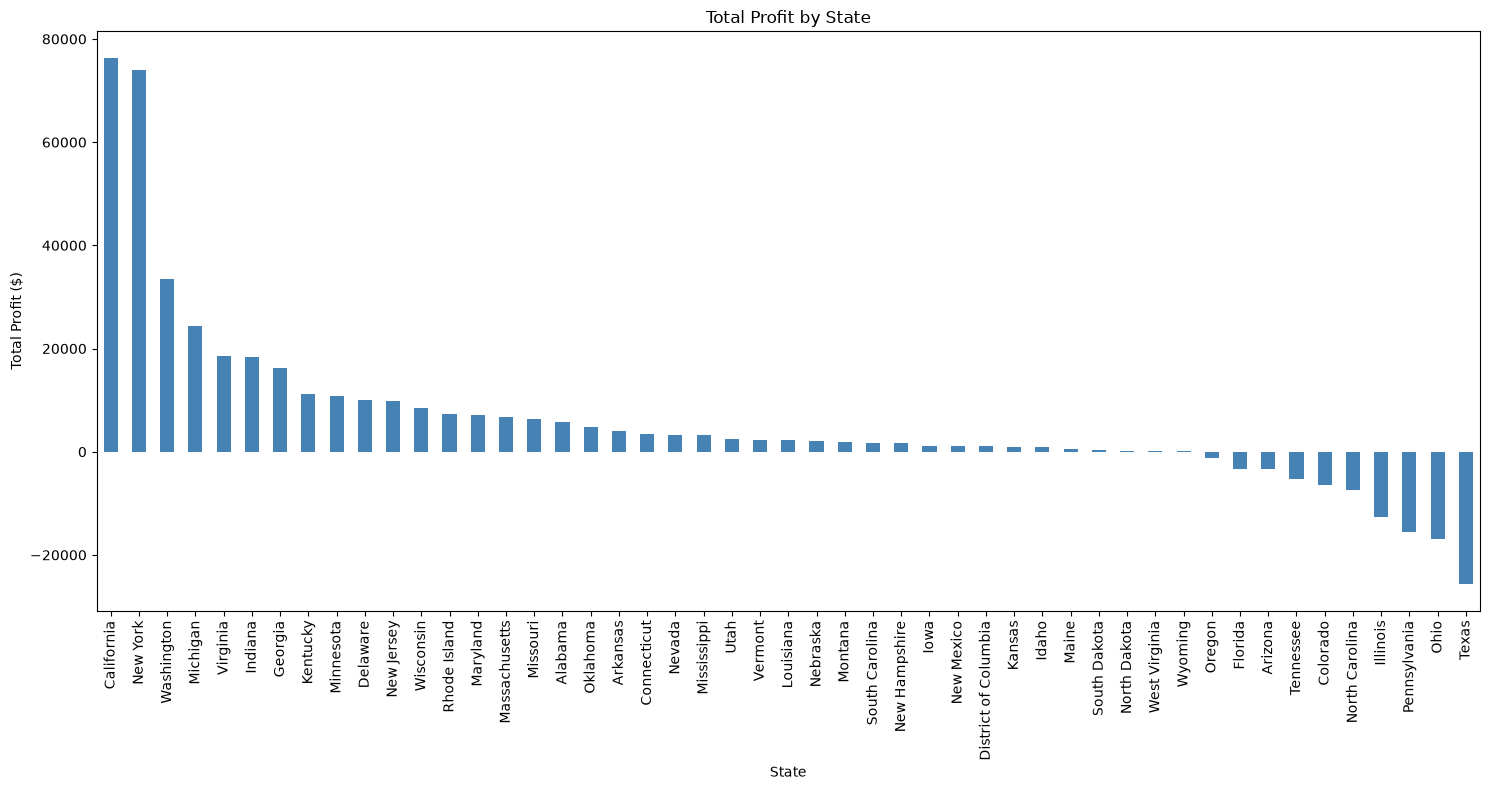

In [12]:
# Display profitability by state

import pandas as pd
import matplotlib.pyplot as plt

# Calculate total profit by state
profit_by_state = (
    df.groupby("State")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

# Display as a list
for state, profit in profit_by_state.items():
    print(f"{state}: ${profit:,.2f}")

# Group proft by state
profit_by_state = df.groupby("State")["Profit"].sum()

# Sort from highest to lowest sales
profit_by_state = profit_by_state.sort_values(ascending=False)

# Create the bar chart
plt.figure(figsize=(15, 8))

profit_by_state.plot(
    kind="bar",
    color="steelblue"
)

# Add title and labels
plt.title("Total Profit by State")
plt.xlabel("State")
plt.ylabel("Total Profit ($)")

# Rotate state names for readability
plt.xticks(rotation=90)

# Improve spacing
plt.tight_layout()

# Display the chart
plt.show()


California has the highest profitability - of almost $80,000, compared Texas which performs the worst which made a loss of over $25,000. New York comes a close second to California.

In [14]:
# See if the Pareto Principle applies to customers. See how much profit is generated by each customer, sort them, calculate their cumulative profit and whether the top 20% account for 80% of the profits.

import pandas as pd

# Calculate total profit per customer
customer_profit = (
    df.groupby("Customer Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Calculate cumulative profit
customer_profit["Cumulative Profit"] = customer_profit["Profit"].cumsum()

# Calculate cumulative profit percentage
total_profit = customer_profit["Profit"].sum()

customer_profit["Cumulative Profit %"] = (
    customer_profit["Cumulative Profit"] / total_profit * 100
)

# Find the number of customers needed to reach 80% of profit
customers_for_80 = (
    customer_profit["Cumulative Profit %"] <= 80
).sum() + 1

# Calculate customer percentage
total_customers = len(customer_profit)

customer_percentage = (
    customers_for_80 / total_customers * 100
)

print(f"Total Customers: {total_customers}")
print(f"Customers generating 80% of profit: {customers_for_80}")
print(f"Percentage of customers: {customer_percentage:.2f}%")
print(f"We can apply the Pareto Principle here, as 19.29% of customers account for 80% of the profits")

Total Customers: 793
Customers generating 80% of profit: 153
Percentage of customers: 19.29%
We can apply the Pareto Principle here, as 19.29% of customers account for 80% of the profits
